change mode to cali...
recv img_l...
recv img_h...
recv img_bg...
recv gain_map...
recv badpts...
recv finish flag...
bg check succ
img_l mean: 9750.551979166667
img_h mean: 11023.65109375
img_bg mean: 9750.551979166667
img_bg min/max: 7026 14402
gain min/max: 0.9218684 1273.1002
badpts: [(75, 59), (92, 48), (111, 68), (255, 255), (255, 255)]


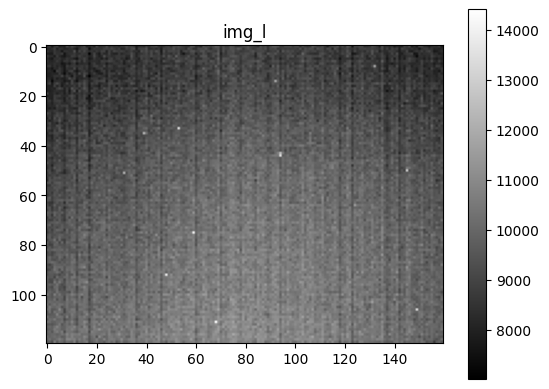

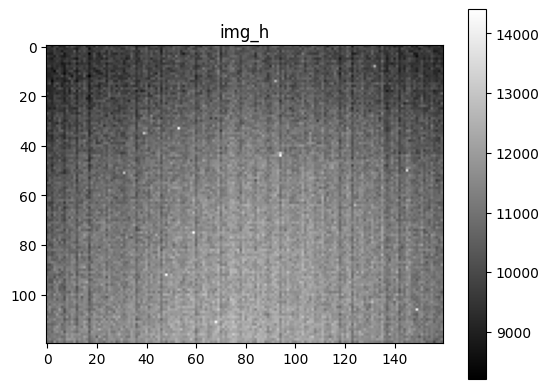

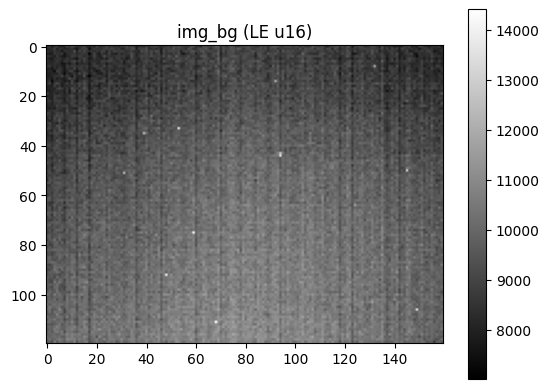

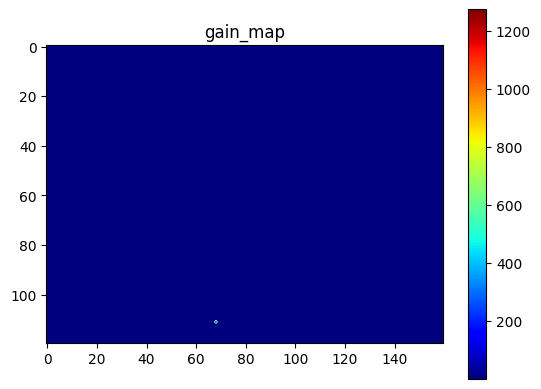

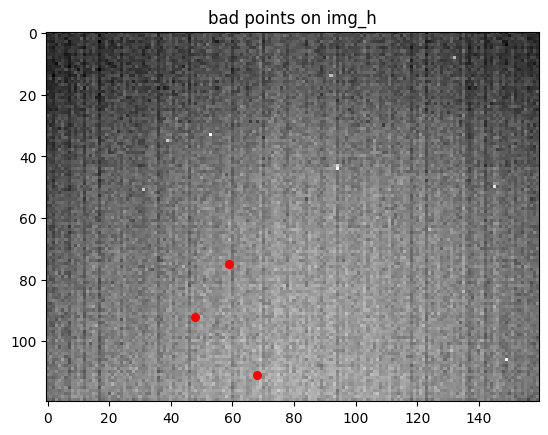

In [19]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import os
import time


PORT = "COM31"
BAUD = 5_000_000

WIDTH = 160
HEIGHT = 120
MAX_BADPT = 5

IMG_PAYLOAD_SIZE   = WIDTH * HEIGHT * 2        # RAW16
GAIN_PAYLOAD_SIZE  = WIDTH * HEIGHT * 4        # float32
BADPT_PAYLOAD_SIZE = MAX_BADPT * 2              # struct BadPt
FINISH_PAYLOAD_SIZE = 2

def to_cali_mode():
    with serial.Serial(PORT, BAUD, timeout=1) as ser:
        ser.write(bytes([0xCC]))

def read_exact(ser, size):
    buf = bytearray()
    while len(buf) < size:
        chunk = ser.read(size - len(buf))
        if not chunk:
            continue
        buf.extend(chunk)
    return bytes(buf)


def read_one_packet(ser, payload_size):
    while True:
        b = ser.read(1)
        if not b:
            continue
        if b[0] == 0xFF:
            b2 = ser.read(1)
            if b2 and b2[0] == 0xFF:
                break

    payload = read_exact(ser, payload_size)
    return payload

def parse_raw16_be(buf, w, h):
    u8 = np.frombuffer(buf, dtype=np.uint8)
    u16 = (u8[0::2].astype(np.uint16) << 8) | u8[1::2]
    return u16.reshape((h, w))


def parse_raw16_le_u16(buf, w, h):
    arr = np.frombuffer(buf, dtype="<u2")
    return arr.reshape((h, w))


def parse_gain_map(buf, w, h):
    return np.frombuffer(buf, dtype="<f4").reshape((h, w))


def parse_badpts(buf):
    pts = []
    for i in range(0, len(buf), 2):
        y = buf[i]
        x = buf[i + 1]
        pts.append((y, x))
    return pts

def parser_finish(buf):
    if buf[0] != buf[1] != 0x78:
        return False
    return True

print("change mode to cali...")
to_cali_mode()
time.sleep(0.5)

with serial.Serial(PORT, BAUD, timeout=1) as ser:
    print("recv img_l...")
    img_l_raw = read_one_packet(ser, IMG_PAYLOAD_SIZE)

    print("recv img_h...")
    img_h_raw = read_one_packet(ser, IMG_PAYLOAD_SIZE)
    
    print("recv img_bg...")
    img_bg_raw = read_one_packet(ser, IMG_PAYLOAD_SIZE)

    print("recv gain_map...")
    gain_raw = read_one_packet(ser, GAIN_PAYLOAD_SIZE)

    print("recv badpts...")
    badpts_raw = read_one_packet(ser, BADPT_PAYLOAD_SIZE)
    
    print("recv finish flag...")
    finish_raw = read_one_packet(ser, FINISH_PAYLOAD_SIZE)

img_l = parse_raw16_be(img_l_raw, WIDTH, HEIGHT)
img_h = parse_raw16_be(img_h_raw, WIDTH, HEIGHT)
img_bg = parse_raw16_le_u16(img_bg_raw, WIDTH, HEIGHT)
gain  = parse_gain_map(gain_raw, WIDTH, HEIGHT)
badpts = parse_badpts(badpts_raw)
fin = parser_finish(finish_raw)

if fin == False:
    raise(RuntimeError("fin check failed"))

if (img_l == img_bg).all():
    print("bg check succ")
else:
    raise(RuntimeError("bg check failed"))

print("img_l mean:", img_l.mean())
print("img_h mean:", img_h.mean())
print("img_bg mean:", img_bg.mean())
print("img_bg min/max:", img_bg.min(), img_bg.max())
print("gain min/max:", gain.min(), gain.max())
print("badpts:", badpts)

plt.figure()
plt.imshow(img_l, cmap="gray")
plt.title("img_l")
plt.colorbar()

plt.figure()
plt.imshow(img_h, cmap="gray")
plt.title("img_h")
plt.colorbar()

plt.figure()
plt.imshow(img_bg, cmap="gray")
plt.title("img_bg (LE u16)")
plt.colorbar()

plt.figure()
plt.imshow(gain, cmap="jet")
plt.title("gain_map")
plt.colorbar()

if badpts:
    filtered = [(y, x) for (y, x) in badpts if not (y == 255 and x == 255)]
    ys = [y for y, _ in filtered]
    xs = [x for _, x in filtered]
    plt.figure()
    plt.imshow(img_h, cmap="gray")
    plt.scatter(xs, ys, c="r", s=30)
    plt.title("bad points on img_h")
    plt.show()

plt.show()

cali_folder = datetime.now().strftime("cali_%Y%m%d_%H%M%S")
cali_folder = os.path.join("cali_data_backup", cali_folder)
os.makedirs(cali_folder, exist_ok=True)
cali_npz_path = os.path.join(cali_folder, "cali.npz")

np.savez(
    cali_npz_path,
    img_l=img_l,
    img_h=img_h,
    gain=gain,
    badpts=np.array(badpts, dtype=np.uint8),
)


Loaded:
 img_l shape: (120, 160)
 img_h shape: (120, 160)


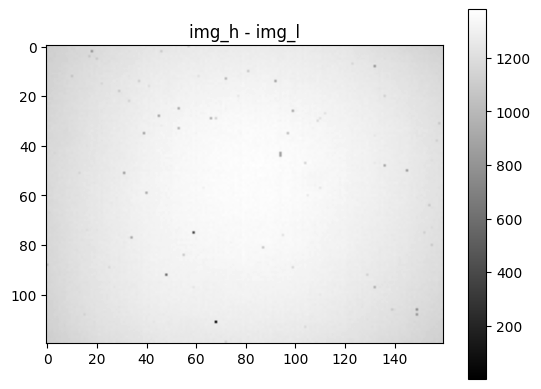

Detected bad points: 3
Bad points coords (y, x):
[[ 75  59]
 [ 92  48]
 [111  68]]
Calibration OK


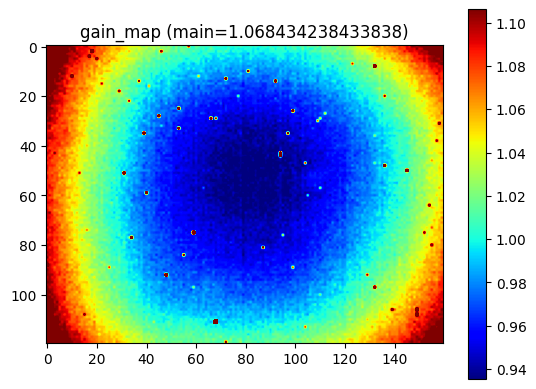

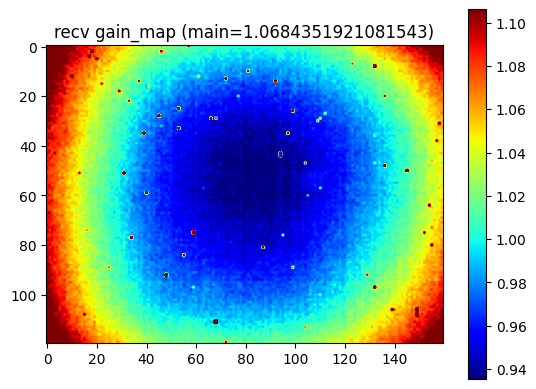

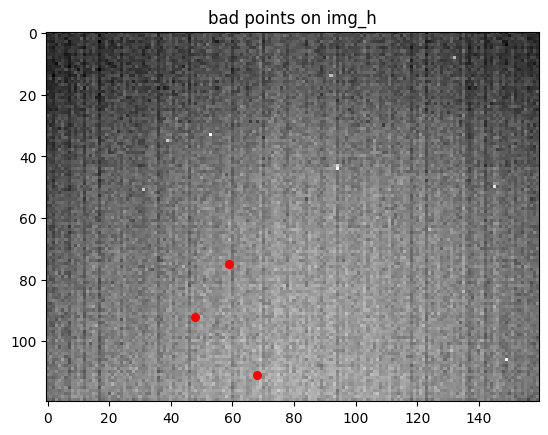

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 配置
# =========================
ENABLE_BADPT_LIMIT = False   # 是否启用坏点限制
BADPT_MAX_NUM = 5
THRESHOLD_RATIO = 0.6
NPZ_PATH = "cali_data_backup/cali_20260209_181009/cali.npz"
OTHER_DATA_IMG = None #["ice_on.npy", "desk_20.5.npy"]

# =========================
# 加载数据
# =========================


if OTHER_DATA_IMG is not None:
    img_l = np.load(OTHER_DATA_IMG[0])
    img_h = np.load(OTHER_DATA_IMG[1])
    img_gain = None
else:
    if NPZ_PATH is None:   
        data = np.load(cali_npz_path)
    else:
        data = np.load(NPZ_PATH)
    img_l = data["img_l"]
    img_h = data["img_h"]
    img_gain = data["gain"]

IMG_H, IMG_W = img_l.shape

print("Loaded:")
print(" img_l shape:", img_l.shape)
print(" img_h shape:", img_h.shape)

# =========================
# 手动校准函数
# =========================
def cali_ref(img_h, img_l, th=0.6, enable_badpt_limit=True):
    """
    校准参考实现：
    - 基底：img_l
    - 坏点：img_h - img_l 过小的点
    - gain_map：avg(diff) / diff
    """
    # 差分
    img_dt = img_h.astype(np.float32) - img_l.astype(np.float32)

    plt.figure()
    plt.imshow(img_dt, cmap="gray")
    plt.title("img_h - img_l")
    plt.colorbar()
    plt.show()

    # ---- 坏点检测 ----
    threshold = np.mean(img_dt) * th
    coords = np.argwhere(img_dt < threshold)  # (y, x)

    print("Detected bad points:", len(coords))

    if enable_badpt_limit:
        # 数量限制
        if len(coords) > BADPT_MAX_NUM:
            print("FAIL: more than 5 bad points!")
            return None, None, None

        # 边缘检查
        for (y, x) in coords:
            if y == 0 or y == IMG_H - 1 or x == 0 or x == IMG_W - 1:
                print("FAIL: bad point on the edge!")
                return None, None, None

        # 相邻检查（任意两点 Chebyshev 距离 <= 1）
        for i in range(len(coords)):
            for j in range(i + 1, len(coords)):
                dy = abs(coords[i][0] - coords[j][0])
                dx = abs(coords[i][1] - coords[j][1])
                if dy <= 1 and dx <= 1:
                    print("FAIL: adjacent bad points!")
                    return None, None, None

    print("Bad points coords (y, x):")
    print(coords)

    # ---- gain_map 计算 ----
    diff = img_h.astype(np.float32) - img_l.astype(np.float32)
    diff[diff == 0] = 1.0  # 防止除零

    avg_diff = np.mean(diff)
    gain_map = avg_diff / diff

    return img_l, coords, gain_map


# =========================
# 执行校准
# =========================
base, badpts, gain_map = cali_ref(
    img_h,
    img_l,
    th=THRESHOLD_RATIO,
    enable_badpt_limit=ENABLE_BADPT_LIMIT,
)

if base is None:
    print("Calibration failed.")
else:
    print("Calibration OK")

    # =========================
    # 可视化结果
    # =========================
    all_data = np.concatenate([gain_map.ravel(), img_gain.ravel()])
    vmin, vmax = np.percentile(all_data, [2, 98])
    
    plt.figure()
    plt.imshow(gain_map, cmap="jet", vmin=vmin, vmax=vmax)
    plt.title(f"gain_map (main={np.mean(gain_map)})")
    plt.colorbar()
    plt.show()
    
    if img_gain is not None:
        plt.figure()
        plt.imshow(img_gain, cmap="jet", vmin=vmin, vmax=vmax)
        plt.title(f"recv gain_map (main={np.mean(img_gain)})")
        plt.colorbar()
        plt.show()

    if badpts is not None and len(badpts) > 0:
        ys = badpts[:, 0]
        xs = badpts[:, 1]

        plt.figure()
        plt.imshow(img_h, cmap="gray")
        plt.scatter(xs, ys, c="r", s=30)
        plt.title("bad points on img_h")
        plt.show()


change mode to cali...
recv img_bg...
recv gain_map...
recv badpts...
recv finish flag...
img_bg mean: 9750.551979166667
img_bg min/max: 7026 14402
gain min/max: 0.9218684 1273.1002
badpts: [(75, 59), (92, 48), (111, 68), (255, 255), (255, 255)]


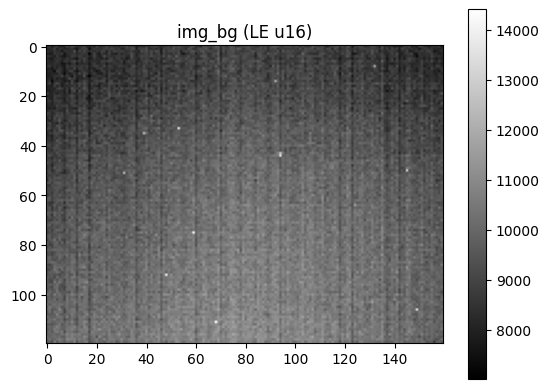

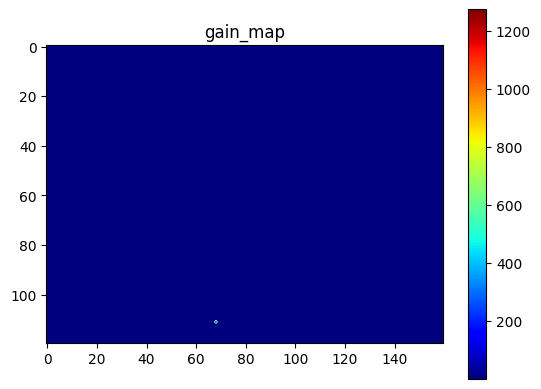

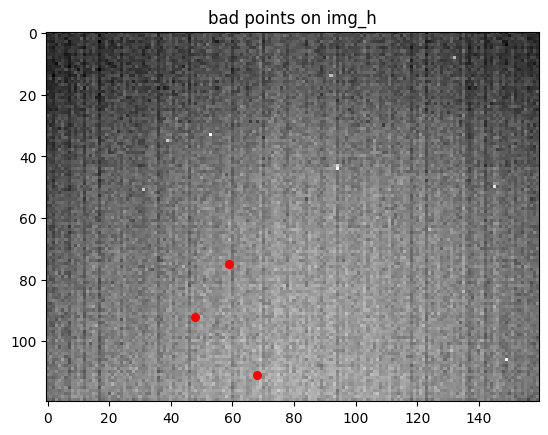

: 

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import os
import time


PORT = "COM31"
BAUD = 5_000_000

WIDTH = 160
HEIGHT = 120
MAX_BADPT = 5

IMG_PAYLOAD_SIZE   = WIDTH * HEIGHT * 2        # RAW16
GAIN_PAYLOAD_SIZE  = WIDTH * HEIGHT * 4        # float32
BADPT_PAYLOAD_SIZE = MAX_BADPT * 2              # struct BadPt
FINISH_PAYLOAD_SIZE = 2

def to_cali_mode():
    with serial.Serial(PORT, BAUD, timeout=1) as ser:
        ser.write(bytes([0xDD]))

def read_exact(ser, size):
    buf = bytearray()
    while len(buf) < size:
        chunk = ser.read(size - len(buf))
        if not chunk:
            continue
        buf.extend(chunk)
    return bytes(buf)


def read_one_packet(ser, payload_size):
    while True:
        b = ser.read(1)
        if not b:
            continue
        if b[0] == 0xFF:
            b2 = ser.read(1)
            if b2 and b2[0] == 0xFF:
                break

    payload = read_exact(ser, payload_size)
    return payload

def parse_raw16_be(buf, w, h):
    u8 = np.frombuffer(buf, dtype=np.uint8)
    u16 = (u8[0::2].astype(np.uint16) << 8) | u8[1::2]
    return u16.reshape((h, w))


def parse_raw16_le_u16(buf, w, h):
    arr = np.frombuffer(buf, dtype="<u2")
    return arr.reshape((h, w))


def parse_gain_map(buf, w, h):
    return np.frombuffer(buf, dtype="<f4").reshape((h, w))


def parse_badpts(buf):
    pts = []
    for i in range(0, len(buf), 2):
        y = buf[i]
        x = buf[i + 1]
        pts.append((y, x))
    return pts

def parser_finish(buf):
    if buf[0] != buf[1] != 0x78:
        return False
    return True

print("change mode to cali...")
to_cali_mode()
time.sleep(0.5)

with serial.Serial(PORT, BAUD, timeout=1) as ser:
    print("recv img_bg...")
    img_bg_raw = read_one_packet(ser, IMG_PAYLOAD_SIZE)

    print("recv gain_map...")
    gain_raw = read_one_packet(ser, GAIN_PAYLOAD_SIZE)

    print("recv badpts...")
    badpts_raw = read_one_packet(ser, BADPT_PAYLOAD_SIZE)
    
    print("recv finish flag...")
    finish_raw = read_one_packet(ser, FINISH_PAYLOAD_SIZE)

img_bg = parse_raw16_le_u16(img_bg_raw, WIDTH, HEIGHT)
gain  = parse_gain_map(gain_raw, WIDTH, HEIGHT)
badpts = parse_badpts(badpts_raw)
fin = parser_finish(finish_raw)

if fin == False:
    raise(RuntimeError("fin check failed"))

print("img_bg mean:", img_bg.mean())
print("img_bg min/max:", img_bg.min(), img_bg.max())
print("gain min/max:", gain.min(), gain.max())
print("badpts:", badpts)

plt.figure()
plt.imshow(img_bg, cmap="gray")
plt.title("img_bg (LE u16)")
plt.colorbar()

plt.figure()
plt.imshow(gain, cmap="jet")
plt.title("gain_map")
plt.colorbar()

if badpts:
    filtered = [(y, x) for (y, x) in badpts if not (y == 255 and x == 255)]
    ys = [y for y, _ in filtered]
    xs = [x for _, x in filtered]
    plt.figure()
    plt.imshow(img_h, cmap="gray")
    plt.scatter(xs, ys, c="r", s=30)
    plt.title("bad points on img_h")
    plt.show()

plt.show()